# 3. First target exploration: Safety Concern and Injury / Illness

Our first candidate targets. **Safety Concern is selected in only 411 reports (4.0%)** and **Injury / Illness in only 6**, so we moved to the six most frequent event categories (notebook 07).

### Run the earlier steps
Loads the variables this notebook needs (`df`, `df_norm`, ...) by running `02_eda_indicators.ipynb` (which runs the steps before it). Output is hidden.

In [1]:
%%capture
%run -i "02_eda_indicators.ipynb"

## 3.1 Locate the candidate target columns

In [2]:
# Normalize whitespace in column names without changing their meaning.
df.columns = (
    df.columns.astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Find the exact target columns in this export.
target_candidates = {
    "Safety Concern": "Events Anomaly / Safety Concern",
    "Injury / Illness": (
        "Events Anomaly / Operating Cab / Car Event - Injury / Illness"
    ),
}

for label, expected_col in target_candidates.items():
    matches = [c for c in df.columns if c == expected_col]
    print(f"\n{label}")
    print("Expected column:", expected_col)
    print("Found:", matches)

# If a column is not found, inspect names containing the relevant terms.
print("\nColumns related to Safety Concern or Injury / Illness:")
for c in df.columns:
    if "Safety Concern" in c or "Injury / Illness" in c:
        print(repr(c))



Safety Concern
Expected column: Events Anomaly / Safety Concern
Found: ['Events Anomaly / Safety Concern']

Injury / Illness
Expected column: Events Anomaly / Operating Cab / Car Event - Injury / Illness
Found: ['Events Anomaly / Operating Cab / Car Event - Injury / Illness']

Columns related to Safety Concern or Injury / Illness:
'Events Anomaly / Operating Cab / Car Event - Injury / Illness'
'Events Anomaly / Safety Concern'


## 3.2 Raw values of the candidate targets

In [3]:

target_cols = list(target_candidates.values())

for col in target_cols:
    if col not in df.columns:
        print(f"Missing column: {col}")
        continue

    print(f"\n{'=' * 70}")
    print(col)
    print("Raw values, including missing values:")
    print(df[col].value_counts(dropna=False).to_string())



Events Anomaly / Safety Concern
Raw values, including missing values:
Events Anomaly / Safety Concern
NaN     9850
True     411

Events Anomaly / Operating Cab / Car Event - Injury / Illness
Raw values, including missing values:
Events Anomaly / Operating Cab / Car Event - Injury / Illness
NaN     10255
True        6


## 3.3 Class distribution

In [4]:

def normalize_binary_target(series):
    """Convert common binary encodings to 1/0; preserve unknowns as NaN."""
    mapping = {
        "true": 1, "false": 0,
        "1": 1, "0": 0,
        "1.0": 1, "0.0": 0,
        "yes": 1, "no": 0,
    }

    def convert(value):
        if pd.isna(value):
            return np.nan
        if isinstance(value, (bool, np.bool_)):
            return int(value)

        key = str(value).strip().lower()
        return mapping.get(key, np.nan)

    return series.map(convert)


label_names = {
    target_candidates["Safety Concern"]: "Safety Concern",
    target_candidates["Injury / Illness"]: "Injury / Illness",
}

target_data = pd.DataFrame(index=df.index)

for col, short_name in label_names.items():
    if col not in df.columns:
        raise KeyError(f"Column not found: {col}")

    target_data[short_name] = normalize_binary_target(df[col])

# Report-level class distribution.
rows = []

for label in target_data.columns:
    y = target_data[label]
    valid = y.notna()
    n_valid = int(valid.sum())
    n_positive = int((y[valid] == 1).sum())
    n_negative = int((y[valid] == 0).sum())
    n_missing_or_unknown = int((~valid).sum())

    rows.append({
        "Label": label,
        "Positive (1)": n_positive,
        "Negative (0)": n_negative,
        "Missing/unknown": n_missing_or_unknown,
        "Valid samples": n_valid,
        "Positive (%)": (
            round(100 * n_positive / n_valid, 2)
            if n_valid else np.nan
        ),
        "Negative (%)": (
            round(100 * n_negative / n_valid, 2)
            if n_valid else np.nan
        ),
    })

distribution_table = pd.DataFrame(rows).set_index("Label")
display(distribution_table)


,Positive (1),Negative (0),Missing/unknown,Valid samples,Positive (%),Negative (%)
Label,,,,,,
Safety Concern,411,0,9850,411,100.0,0.0
Injury / Illness,6,0,10255,6,100.0,0.0


## 3.4 Class distribution plot

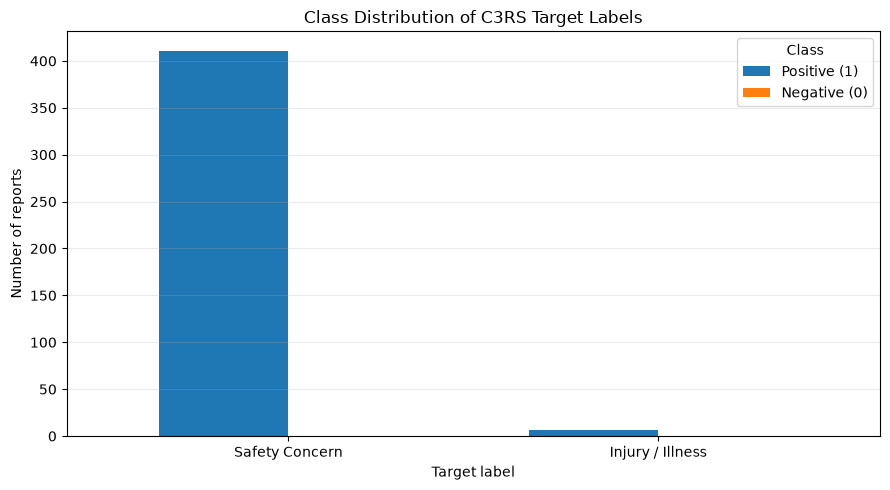

In [5]:

plot_data = distribution_table[
    ["Positive (1)", "Negative (0)"]
].copy()

ax = plot_data.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0,
    width=0.7
)

ax.set_title("Class Distribution of C3RS Target Labels")
ax.set_xlabel("Target label")
ax.set_ylabel("Number of reports")
ax.legend(title="Class")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()
